# Day-ahead price model

1. **Feature pipeline** (`features.py`): turns the Section 3 scheduler inputs into 24 rows of features.
2. **Price predictor** (`price_predictor.py`): local supply curve + robust ridge correction, NumPy only.

Training and inference share `build_features`, so the day's realized prices and net load cannot leak in.

In [1]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from features import BASE, build_dataset, build_features, load_days, scheduler_inputs
from price_predictor import PricePredictor, metrics, predict_prices, walk_forward

CSV = next(p for p in (Path('training_data.csv'), Path('../training_data.csv')) if p.exists())

## 1. Features

In [2]:
days = load_days(CSV)
X, Y, names, idx = build_dataset(days)
print('days x hours x features:', X.shape)
pd.DataFrame(X[0], columns=names, index=pd.RangeIndex(1, 25, name='hour')).round(2).head()

days x hours x features: (359, 24, 20)


,curve_near_hour,curve_all_hours,curve_yesterday,price_lag1,price_med7,price_day_lag1,price_day_mean7,price_std7,load,load_ramp,load_vs_lag1,load_vs_week,err_lag1,err_week,weekend,monday,hour_sin1,hour_cos1,hour_sin2,hour_cos2
hour,,,,,,,,,,,,,,,,,,,,
1,62.17,1.93,10.34,6.17,-12.77,-7.31,-13.22,17.89,19.84,-0.84,2.82,0.19,1.37,0.06,0.0,1.0,0.00,1.00,0.00,1.00
2,59.44,2.91,11.32,4.33,-10.20,-4.58,-10.50,17.89,19.00,-1.14,2.44,0.13,1.33,0.18,0.0,1.0,0.26,0.97,0.50,0.87
3,58.25,3.63,11.89,2.57,-12.31,-3.39,-9.31,17.89,18.71,-0.21,2.62,0.39,1.01,0.13,0.0,1.0,0.50,0.87,0.87,0.50
4,58.04,3.96,12.27,2.20,-13.20,-3.17,-9.09,17.89,18.79,0.87,2.76,0.68,0.42,0.00,0.0,1.0,0.71,0.71,1.00,0.00
5,59.58,3.91,12.38,2.20,-14.56,-4.72,-10.64,17.89,19.57,2.45,3.38,1.18,0.00,-0.05,0.0,1.0,0.87,0.50,0.87,-0.50


**Leakage check.** Corrupt day *i*'s realized data and everything after it; the features for day *i* must not change.

In [3]:
i = 200
bad = copy.deepcopy(days)
bad['price'][i:] = 1e6
bad['net_load'][i:] = -1e6
bad['forecast'][i + 1:] = 7e5
assert np.array_equal(build_features(**scheduler_inputs(days, i))[0],
                      build_features(**scheduler_inputs(bad, i))[0])
print('no leakage')

no leakage


## 2. Walk-forward evaluation

Every 15 days the model is refit on earlier days only, then predicts the next 15. Curve and model settings were tuned on days 90-268. Days 269 onward were left out of that tuning, but an earlier comparison of model types used the whole year, so this is not a fully untouched holdout. The holdout (about October-December) also has no extreme price spikes.

In [4]:
FIRST, SPLIT = 90, 269
pred = walk_forward(X, Y, names, first=FIRST)
actual = Y[FIRST:]
cands = {
    'yesterday': days['price'][idx - 1][FIRST:],
    '7-day median': np.stack([np.median(days['price'][j - 7:j], axis=0) for j in idx])[FIRST:],
    'supply curve only': X[FIRST:, :, names.index(BASE)],
    'model': pred,
}
k = SPLIT - FIRST
rows = {(part, n): metrics(p[s], actual[s])
        for part, s in (('tuning days', slice(0, k)), ('holdout', slice(k, None))) for n, p in cands.items()}
pd.DataFrame(rows).T.round(3)

MAE    RMSE  median_AE  rank_corr  \
tuning days yesterday          7.968  19.092      4.365      0.933   
            7-day median       9.776  23.255      5.483      0.928   
            supply curve only  5.194  13.505      2.878      0.957   
            model              5.079  13.448      2.854      0.958   
holdout     yesterday          6.278   8.865      4.607      0.912   
            7-day median       6.456   9.239      4.678      0.921   
            supply curve only  3.937   5.466      3.091      0.952   
            model              3.718   5.058      2.816      0.958   

                               spread_capture  
tuning days yesterday                   0.969  
            7-day median                0.968  
            supply curve only           0.970  
            model                       0.971  
holdout     yesterday                   0.945  
            7-day median                0.938  
            supply curve only           0.967  
            model                       0.967

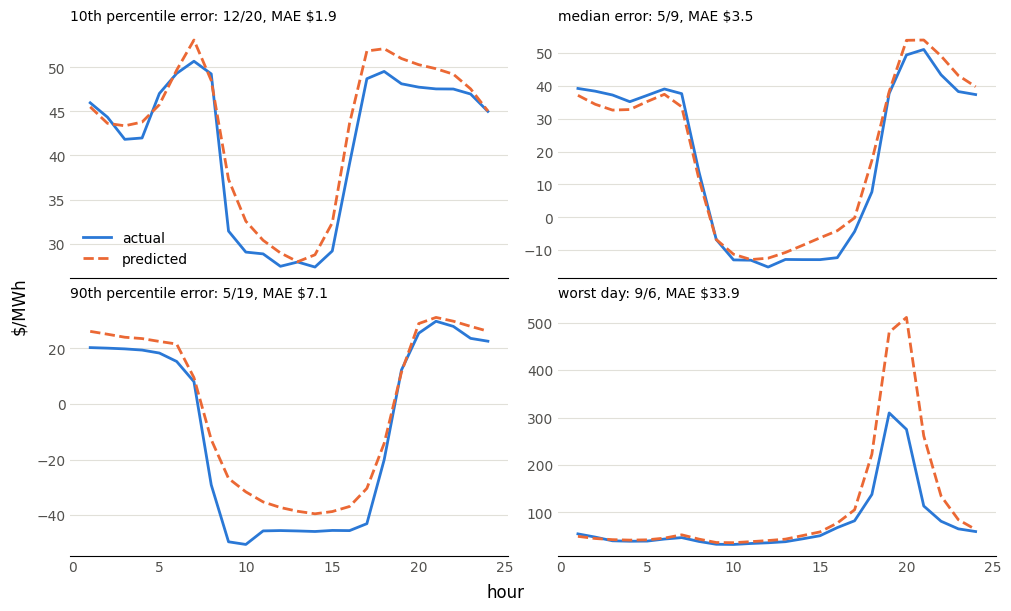

In [5]:
BLUE, ORANGE, INK, GRID = '#2a78d6', '#eb6834', '#52514e', '#e1e0d9'

def style(ax, title):
    ax.set_title(title, loc='left', fontsize=10)
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.tick_params(colors=INK, length=0)

# Days at the 10th, 50th, 90th percentile of daily error, and the worst day.
daily = np.abs(pred - actual).mean(1)
order = np.argsort(daily)
picks = [order[int(q * (len(order) - 1))] for q in (0.1, 0.5, 0.9, 1.0)]
labels = ['10th percentile error', 'median error', '90th percentile error', 'worst day']
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, layout='constrained')
for ax, d, lab in zip(axes.flat, picks, labels):
    j = idx[FIRST + d]
    ax.plot(range(1, 25), actual[d], color=BLUE, lw=2, label='actual')
    ax.plot(range(1, 25), pred[d], color=ORANGE, lw=2, ls='--', label='predicted')
    style(ax, f"{lab}: {days['month'][j]}/{days['day'][j]}, MAE ${daily[d]:.1f}")
axes[0, 0].legend(frameon=False)
fig.supxlabel('hour'); fig.supylabel('$/MWh')
plt.show()

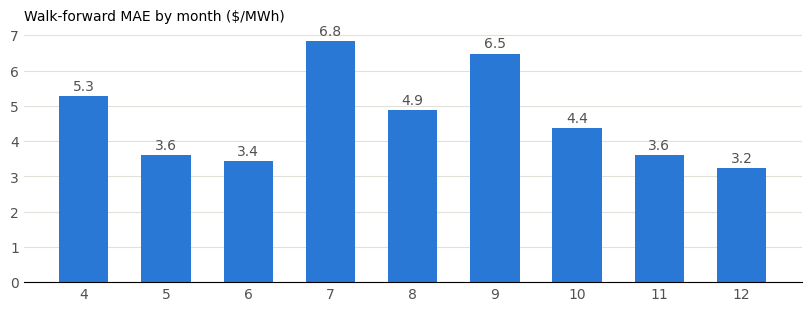

In [6]:
months = days['month'][idx][FIRST:]
mae = pd.Series(daily).groupby(months).mean()
fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
bars = ax.bar(mae.index.astype(str), mae, color=BLUE, width=0.6)
ax.bar_label(bars, fmt='%.1f', color=INK, padding=2)
style(ax, 'Walk-forward MAE by month ($/MWh)')
plt.show()

## 3. Final model

Fit on all days and save. `predict_prices` takes the scheduler's inputs directly.

In [7]:
PricePredictor().fit(X, Y, names).save()
prices = predict_prices(**scheduler_inputs(days, len(days['price']) - 1))
assert prices.shape == (24,) and np.isfinite(prices).all()
prices.round(2)

array([37.38, 34.83, 33.86, 34.48, 36.56, 39.05, 41.05, 38.51, 29.93,
       25.49, 25.34, 24.05, 23.6 , 23.13, 24.15, 32.35, 43.71, 45.98,
       45.8 , 44.67, 44.06, 43.26, 42.63, 41.59])

In [8]:
model = PricePredictor.load()
pd.Series(model.coef, model.names, name='$/MWh per 1 std').sort_values(key=abs, ascending=False).round(2)

curve_yesterday    2.96
price_lag1         1.97
load_vs_lag1       1.47
curve_near_hour   -1.05
price_std7        -0.57
load_vs_week       0.50
load               0.49
price_day_lag1     0.48
load_ramp          0.47
price_day_mean7   -0.42
err_week          -0.40
monday             0.39
err_lag1           0.31
hour_cos2         -0.23
weekend           -0.11
hour_sin1          0.11
hour_sin2         -0.10
curve_all_hours   -0.05
price_med7        -0.05
hour_cos1         -0.04
Name: $/MWh per 1 std, dtype: float64